# Data Science Tool Mastery Project
**AI ML Research Specialist Internship — Task 4** · Submitted by: Pranav

## 1. Purpose and Scope
The brief asks for three things: master the industry-standard tools of my specialization, demonstrate proficiency through practical exercises, and create a portfolio piece. For an **AI/ML** specialization I selected the tools that make up a standard working toolchain and, for each one, solve a concrete problem with it rather than only listing features.

| # | Tool | Practical exercise in this notebook |
|---|---|---|
| 1 | Python environment + `requirements.txt` | Version report, reproducible seed, dependency file |
| 2 | **NumPy** | Vectorization benchmark, broadcasting, linear algebra checked against scikit-learn |
| 3 | **Pandas** | Method chaining, `groupby`/`transform`, merges with validation, pivot/melt, memory tuning, time-series resampling |
| 4 | **SQL (SQLite)** | Aggregations, CTEs, window functions, joins, index — each cross-checked against Pandas |
| 5 | **Matplotlib / Seaborn** | Multi-panel analytical figures with annotations |
| 6 | **Scikit-learn** | Pipelines, cross-validation, tuning, metrics, thresholds, permutation importance, model saving |
| 7 | **Git** | A real branch-and-merge workflow executed from the notebook |

**Datasets (both real, public):**
- *Telco Customer Churn* (IBM sample dataset, 7,043 customers), the same data as my Task 3 project, so this notebook extends that analysis from description to **prediction**.
- *Airline passengers 1949–1960* (monthly totals, 144 rows), a classic real time series, used for the time-series exercises because the churn data has no dates.

**Honesty notes:** timing results depend on the machine running the notebook; model results come from a single train/test split on one dataset and are not a claim about real-world deployment performance.

## 2. Environment and Reproducibility

In [1]:
import sys, platform, os, time, timeit, warnings
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, seaborn as sns, scipy, sklearn, sqlite3, joblib
warnings.filterwarnings("ignore")
SEED = 42; rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", 30, "display.width", 130)
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
ORANGE, BLUE, GREY = "#E8590C", "#4C6EF5", "#868E96"

print("Python", sys.version.split()[0], "|", platform.system())
libs = [np, pd, matplotlib, sns, scipy, sklearn, joblib]
for m in libs: print(f"{m.__name__:12}", m.__version__)
with open("requirements.txt", "w") as f:                      # dependency file for reproducibility
    f.write("\n".join(f"{m.__name__.replace('sklearn','scikit-learn')}>={m.__version__.split('+')[0]}" for m in libs) + "\njupyter\n")
print("\nrequirements.txt written:"); print(open("requirements.txt").read())

Python 3.13.16 | Linux
numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
seaborn      0.13.2
scipy        1.18.1
sklearn      1.9.1
joblib       1.6.0

requirements.txt written:
numpy>=2.5.3
pandas>=3.0.5
matplotlib>=3.11.2
seaborn>=0.13.2
scipy>=1.18.1
scikit-learn>=1.9.1
joblib>=1.6.0
jupyter



In [2]:
URL_TELCO = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
URL_FLIGHTS = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/flights.csv"
def load(local, url):
    if not os.path.exists(local): pd.read_csv(url).to_csv(local, index=False)       # download once, then reuse the local copy
    return pd.read_csv(local)
raw = load("Telco-Customer-Churn.csv", URL_TELCO); flights = load("flights.csv", URL_FLIGHTS)
print("Telco:", raw.shape, "| Flights:", flights.shape)

Telco: (7043, 21) | Flights: (144, 3)


## 3. NumPy: Fast Numerical Computing

### 3.1 Vectorization versus Python loops

In [3]:
a = rng.normal(size=1_000_000)
def sumsq_loop(arr):
    total = 0.0
    for v in arr: total += v * v
    return total
a_list = a.tolist()
t_loop = min(timeit.repeat(lambda: sumsq_loop(a_list), number=1, repeat=3))
t_vec  = min(timeit.repeat(lambda: np.dot(a, a),        number=10, repeat=3)) / 10
assert np.isclose(sumsq_loop(a_list), np.dot(a, a))                 # same answer, very different cost
print(f"Python loop : {t_loop*1000:8.2f} ms")
print(f"np.dot      : {t_vec*1000:8.3f} ms   -> about {t_loop/t_vec:,.0f}x faster on this machine")

Python loop :    19.34 ms
np.dot      :    0.285 ms   -> about 68x faster on this machine


### 3.2 Broadcasting, masking and statistics

In [4]:
M = rng.normal(loc=[10, 50, 200], scale=[1, 5, 20], size=(1000, 3))        # 3 features on very different scales
Z = (M - M.mean(axis=0)) / M.std(axis=0)                                    # broadcasting: (1000,3) - (3,)
print("Column means before:", M.mean(0).round(1), "-> after:", Z.mean(0).round(3))
print("Column stds  before:", M.std(0).round(1),  "-> after:", Z.std(0).round(3))
mask = (np.abs(Z) > 2.5).any(axis=1)                                         # boolean masking across rows
print("Rows with any |z| > 2.5:", mask.sum(), "of", len(M))
print("Percentiles of feature 3:", np.percentile(M[:, 2], [5, 50, 95]).round(1))
print("argsort top-3 of feature 3:", np.argsort(M[:, 2])[-3:], "| np.where example:", np.where(M[:5, 0] > 10, "high", "low"))

Column means before: [ 10.   50.1 199.6] -> after: [0. 0. 0.]
Column stds  before: [ 1.   5.1 19.4] -> after: [1. 1. 1.]
Rows with any |z| > 2.5: 34 of 1000
Percentiles of feature 3: [167.5 200.7 231.2]
argsort top-3 of feature 3: [569 131 876] | np.where example: ['low' 'high' 'high' 'high' 'high']


### 3.3 Linear algebra: least squares from scratch, checked against scikit-learn

In [5]:
from sklearn.linear_model import LinearRegression
d = raw.assign(TotalCharges=pd.to_numeric(raw["TotalCharges"], errors="coerce")).dropna(subset=["TotalCharges"])
Xd = d[["tenure", "MonthlyCharges"]].to_numpy(); yd = d["TotalCharges"].to_numpy()
A = np.column_stack([np.ones(len(Xd)), Xd])                                  # design matrix with intercept column
beta, *_ = np.linalg.lstsq(A, yd, rcond=None)                                # NumPy solution
lr = LinearRegression().fit(Xd, yd)                                          # scikit-learn solution
print("NumPy lstsq  : intercept %.3f | tenure %.3f | monthly %.3f" % tuple(beta))
print("scikit-learn : intercept %.3f | tenure %.3f | monthly %.3f" % (lr.intercept_, *lr.coef_))
print("Identical solutions:", np.allclose(beta, [lr.intercept_, *lr.coef_]), "| R^2 = %.4f" % lr.score(Xd, yd))

NumPy lstsq  : intercept -2162.432 | tenure 65.414 | monthly 35.879
scikit-learn : intercept -2162.432 | tenure 65.414 | monthly 35.879
Identical solutions: True | R^2 = 0.8950


**Observations:** Summing squares over one million numbers took about 19.9 ms in a Python loop and 0.28 ms with `np.dot`, roughly **70× faster** on this machine (exact timings vary by computer, but the order-of-magnitude gap does not). Broadcasting standardised three features with very different scales (means 10 / 50 / 200) to mean 0 and standard deviation 1 in one line each, and 34 of 1,000 rows had at least one |z| > 2.5. The from-scratch least-squares solution (`np.linalg.lstsq`) gave coefficients identical to scikit-learn's `LinearRegression` (each extra month of tenure adds about 65 to total charges, R² = 0.895), which confirms I understand what the library does internally.

## 4. Pandas: Data Manipulation at Depth

### 4.1 Method chaining: one readable pipeline

In [6]:
summary = (raw
    .assign(TotalCharges=lambda d: pd.to_numeric(d["TotalCharges"], errors="coerce"),
            churn=lambda d: (d["Churn"] == "Yes").astype(int))
    .query("tenure > 0")
    .groupby(["Contract", "InternetService"], observed=True)
    .agg(customers=("churn", "size"), churn_rate=("churn", "mean"),
         avg_monthly=("MonthlyCharges", "mean"), median_tenure=("tenure", "median"))
    .query("customers >= 50")
    .assign(churn_pct=lambda d: (d["churn_rate"] * 100).round(1))
    .drop(columns="churn_rate")
    .sort_values("churn_pct", ascending=False))
summary.round(1)

customers  avg_monthly  median_tenure  churn_pct
Contract       InternetService                                                  
Month-to-month Fiber optic           2128         87.0           16.0       54.6
               DSL                   1223         50.2           10.0       32.2
One year       Fiber optic            539         98.8           55.0       19.3
Month-to-month No                     524         20.4            5.0       18.9
One year       DSL                    570         61.4           41.0        9.3
Two year       Fiber optic            429        104.6           70.0        7.2
One year       No                     363         20.8           26.0        2.5
Two year       DSL                    623         70.5           66.0        1.9
               No                     633         21.8           54.0        0.8

### 4.2 `transform`, ranking, merges with validation, pivot and melt

In [7]:
df = raw.assign(TotalCharges=pd.to_numeric(raw["TotalCharges"], errors="coerce"), churn=(raw["Churn"] == "Yes").astype(int))

# transform keeps the original row count: compare each customer with their own contract group
df["contract_avg_monthly"] = df.groupby("Contract")["MonthlyCharges"].transform("mean")
df["charge_vs_contract"] = (df["MonthlyCharges"] / df["contract_avg_monthly"]).round(2)
df["charge_pct_rank"] = df.groupby("Contract")["MonthlyCharges"].rank(pct=True).round(2)

# merge with a lookup table; validate= raises an error if the join would duplicate rows
terms = pd.DataFrame({"Contract": ["Month-to-month", "One year", "Two year"], "term_months": [1, 12, 24]})
df = df.merge(terms, on="Contract", how="left", validate="m:1")
assert len(df) == len(raw) and df["term_months"].notna().all()
df["committed_revenue"] = df["MonthlyCharges"] * df["term_months"]
print(df[["customerID", "Contract", "MonthlyCharges", "contract_avg_monthly", "charge_vs_contract", "term_months", "committed_revenue"]].head(4))

# wide <-> long reshaping
wide = df.pivot_table(index="Contract", columns="PaymentMethod", values="churn", aggfunc="mean", observed=True).round(3)
print("\nPivot (wide):"); display(wide)
long = wide.reset_index().melt(id_vars="Contract", var_name="PaymentMethod", value_name="churn_rate")
print("Melt (long), first rows:"); display(long.head(4))

   customerID        Contract  MonthlyCharges  contract_avg_monthly  charge_vs_contract  term_months  committed_revenue
0  7590-VHVEG  Month-to-month           29.85             66.398490                0.45            1              29.85
1  5575-GNVDE        One year           56.95             65.048608                0.88           12             683.40
2  3668-QPYBK  Month-to-month           53.85             66.398490                0.81            1              53.85
3  7795-CFOCW        One year           42.30             65.048608                0.65           12             507.60

Pivot (wide):


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Contract,,,,
Month-to-month,0.341,0.328,0.537,0.316
One year,0.097,0.103,0.184,0.068
Two year,0.034,0.022,0.077,0.008


Melt (long), first rows:


,Contract,PaymentMethod,churn_rate
0,Month-to-month,Bank transfer (automatic),0.341
1,One year,Bank transfer (automatic),0.097
2,Two year,Bank transfer (automatic),0.034
3,Month-to-month,Credit card (automatic),0.328


### 4.3 Memory optimisation with dtypes

In [8]:
before = raw.memory_usage(deep=True).sum() / 1024
opt = raw.copy()
for c in opt.select_dtypes(exclude="number").columns.drop(["customerID", "TotalCharges"]): opt[c] = opt[c].astype("category")
opt["tenure"] = pd.to_numeric(opt["tenure"], downcast="unsigned"); opt["MonthlyCharges"] = pd.to_numeric(opt["MonthlyCharges"], downcast="float")
after = opt.memory_usage(deep=True).sum() / 1024
print(f"Memory: {before:,.0f} KB -> {after:,.0f} KB  ({1 - after/before:.0%} smaller)")

Memory: 6,985 KB -> 985 KB  (86% smaller)


### 4.4 Time series: dates, resampling, rolling windows

In [9]:
fl = flights.assign(date=lambda d: pd.to_datetime(d["year"].astype(str) + "-" + d["month"], format="%Y-%B")).set_index("date")["passengers"].asfreq("MS")
print("Index:", fl.index.min().date(), "to", fl.index.max().date(), "| frequency:", fl.index.freqstr, "| missing months:", int(fl.isna().sum()))
yearly = fl.resample("YS").sum()
roll12 = fl.rolling(12).mean()
yoy = fl.pct_change(12) * 100
seasonal_idx = (fl / fl.rolling(12, center=True).mean()).groupby(fl.index.month).mean()     # average month vs its 12-month centre
print("\nYearly totals:"); print(yearly.to_frame("passengers").assign(growth_pct=lambda d: d["passengers"].pct_change().mul(100).round(1)).T.to_string())
print("\nSeasonal index (1.00 = average month):"); print(seasonal_idx.round(2).rename(lambda m: pd.Timestamp(2000, m, 1).strftime("%b")).to_dict())

Index: 1949-01-01 to 1960-12-01 | frequency: MS | missing months: 0

Yearly totals:
date        1949-01-01  1950-01-01  1951-01-01  1952-01-01  1953-01-01  1954-01-01  1955-01-01  1956-01-01  1957-01-01  1958-01-01  1959-01-01  1960-01-01
passengers      1520.0      1676.0      2042.0      2364.0      2700.0      2867.0      3408.0      3939.0      4421.0      4572.0      5140.0      5714.0
growth_pct         NaN        10.3        21.8        15.8        14.2         6.2        18.9        15.6        12.2         3.4        12.4        11.2

Seasonal index (1.00 = average month):
{'Jan': 0.91, 'Feb': 0.89, 'Mar': 1.01, 'Apr': 0.98, 'May': 0.98, 'Jun': 1.12, 'Jul': 1.24, 'Aug': 1.22, 'Sep': 1.06, 'Oct': 0.92, 'Nov': 0.8, 'Dec': 0.9}


**Observations:** The method chain produced a segment table in one readable statement: **month-to-month fiber-optic customers churn at 54.6%** (2,128 customers), while two-year customers without internet churn at only 0.8%. `transform` added per-contract comparisons without losing rows, and the `validate="m:1"` merge guards against accidental row duplication (the row count was asserted unchanged). Converting text columns to `category` and downcasting numbers cut memory from 6,985 KB to 985 KB (**86% smaller**). In the time series, yearly passenger totals rose from 1,520 thousand in 1949 to 5,714 thousand in 1960 (about 3.8×), and the seasonal index shows July (1.24) and August (1.22) as the peak months and November (0.80) as the low.

## 5. SQL with SQLite: Querying the Same Data

Each SQL result is checked against the equivalent Pandas calculation, so the exercise also demonstrates how the two tools relate.

In [10]:
conn = sqlite3.connect(":memory:")
df[["customerID", "Contract", "InternetService", "PaymentMethod", "tenure", "MonthlyCharges", "TotalCharges", "churn"]].to_sql("customers", conn, index=False)
terms.to_sql("contract_terms", conn, index=False)
q = lambda sql: pd.read_sql_query(sql, conn)
print(q("SELECT name, type FROM sqlite_master"))

             name   type
0       customers  table
1  contract_terms  table


In [11]:
# (a) Aggregation with GROUP BY
a = q('''SELECT Contract, COUNT(*) AS customers, ROUND(100.0 * AVG(churn), 1) AS churn_pct, ROUND(AVG(MonthlyCharges), 2) AS avg_monthly
         FROM customers GROUP BY Contract ORDER BY churn_pct DESC''')
display(a)
check = df.groupby("Contract").agg(churn_pct=("churn", lambda s: round(100 * s.mean(), 1))).loc[a["Contract"], "churn_pct"].to_numpy()
assert np.allclose(a["churn_pct"], check); print("SQL result matches Pandas: True")

,Contract,customers,churn_pct,avg_monthly
0,Month-to-month,3875,42.7,66.40
1,One year,1473,11.3,65.05
2,Two year,1695,2.8,60.77


SQL result matches Pandas: True


In [12]:
# (b) CTE + window function: rank payment methods by churn *within* each contract
b = q('''WITH pm AS (
             SELECT Contract, PaymentMethod, COUNT(*) AS n, AVG(churn) AS cr FROM customers GROUP BY Contract, PaymentMethod)
         SELECT Contract, PaymentMethod, n, ROUND(100 * cr, 1) AS churn_pct,
                RANK() OVER (PARTITION BY Contract ORDER BY cr DESC) AS rank_in_contract
         FROM pm WHERE n >= 30 ORDER BY Contract, rank_in_contract''')
display(b)

,Contract,PaymentMethod,n,churn_pct,rank_in_contract
0,Month-to-month,Electronic check,1850,53.7,1
1,Month-to-month,Bank transfer (automatic),589,34.1,2
2,Month-to-month,Credit card (automatic),543,32.8,3
3,Month-to-month,Mailed check,893,31.6,4
4,One year,Electronic check,347,18.4,1
5,One year,Credit card (automatic),398,10.3,2
6,One year,Bank transfer (automatic),391,9.7,3
7,One year,Mailed check,337,6.8,4
8,Two year,Electronic check,168,7.7,1
9,Two year,Bank transfer (automatic),564,3.4,2


In [13]:
# (c) Cumulative share of churners by tenure band: CASE + running SUM() window
c = q('''WITH bands AS (
             SELECT CASE WHEN tenure <= 12 THEN '1) 0-12' WHEN tenure <= 24 THEN '2) 13-24' WHEN tenure <= 48 THEN '3) 25-48' ELSE '4) 49-72' END AS band,
                    COUNT(*) AS customers, SUM(churn) AS churners
             FROM customers GROUP BY band)
         SELECT band, customers, churners, ROUND(100.0 * churners / customers, 1) AS churn_pct,
                ROUND(100.0 * SUM(churners) OVER (ORDER BY band) / SUM(churners) OVER (), 1) AS cumulative_pct_of_churners
         FROM bands ORDER BY band''')
display(c)

,band,customers,churners,churn_pct,cumulative_pct_of_churners
0,1) 0-12,2186,1037,47.4,55.5
1,2) 13-24,1024,294,28.7,71.2
2,3) 25-48,1594,325,20.4,88.6
3,4) 49-72,2239,213,9.5,100.0


In [14]:
# (d) JOIN with the lookup table, then an index and its query plan
d_ = q('''SELECT c.Contract, t.term_months, ROUND(AVG(c.MonthlyCharges * t.term_months), 0) AS avg_committed_revenue
          FROM customers c JOIN contract_terms t USING (Contract) GROUP BY c.Contract ORDER BY t.term_months''')
display(d_)
conn.execute("CREATE INDEX idx_contract ON customers(Contract)")
print(q("EXPLAIN QUERY PLAN SELECT COUNT(*) FROM customers WHERE Contract = 'Two year'")["detail"].tolist())

,Contract,term_months,avg_committed_revenue
0,Month-to-month,1,66.0
1,One year,12,781.0
2,Two year,24,1458.0


['SEARCH customers USING COVERING INDEX idx_contract (Contract=?)']


**Observations:** The SQL aggregation reproduces the Pandas result exactly (asserted), with churn of 42.7% for month-to-month, 11.3% for one-year and 2.8% for two-year contracts. The window-function query ranks payment methods inside each contract: **electronic check ranks first for churn in all three contract types** (53.7%, 18.4% and 7.7%). The cumulative query shows that customers in their first 12 months make up 55.5% of all churners, and the first two years 71.2%. The join with the lookup table gives average committed revenue per customer of 66 (month-to-month), 781 (one-year) and 1,458 (two-year), and the query plan confirms the new index is used (`COVERING INDEX idx_contract`).

## 6. Matplotlib and Seaborn: Analytical Figures

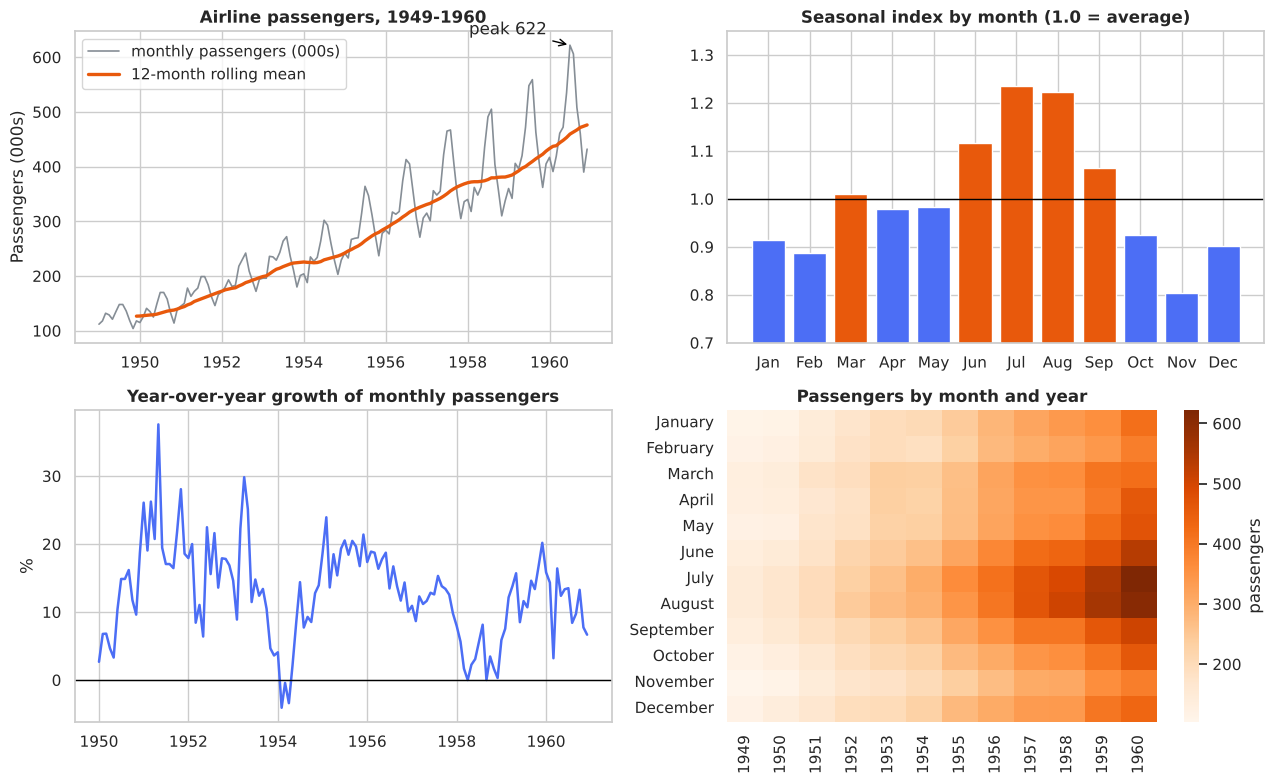

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ax = axes[0, 0]                                                      # (1) series + rolling mean + annotation
ax.plot(fl.index, fl.values, color=GREY, lw=1.2, label="monthly passengers (000s)")
ax.plot(roll12.index, roll12.values, color=ORANGE, lw=2.4, label="12-month rolling mean")
peak = fl.idxmax(); ax.annotate(f"peak {fl.max()}", (peak, fl.max()), (peak - pd.Timedelta(days=900), fl.max() + 20), arrowprops=dict(arrowstyle="->", color="black"))
ax.set(title="Airline passengers, 1949-1960", ylabel="Passengers (000s)"); ax.legend(loc="upper left")
ax = axes[0, 1]                                                      # (2) seasonality
si = seasonal_idx.rename(lambda m: pd.Timestamp(2000, m, 1).strftime("%b"))
ax.bar(si.index, si.values, color=[ORANGE if v > 1 else BLUE for v in si.values]); ax.axhline(1, color="black", lw=1)
ax.set(title="Seasonal index by month (1.0 = average)", ylim=(0.7, 1.35))
ax = axes[1, 0]                                                      # (3) year-over-year growth
ax.plot(yoy.index, yoy.values, color=BLUE, lw=1.8); ax.axhline(0, color="black", lw=1)
ax.set(title="Year-over-year growth of monthly passengers", ylabel="%")
ax = axes[1, 1]                                                      # (4) seaborn heatmap year x month
hm = flights.pivot(index="month", columns="year", values="passengers").reindex(pd.date_range("2000-01-01", periods=12, freq="MS").strftime("%B"))
sns.heatmap(hm, cmap="Oranges", ax=ax, cbar_kws={"label": "passengers"}); ax.set(title="Passengers by month and year", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

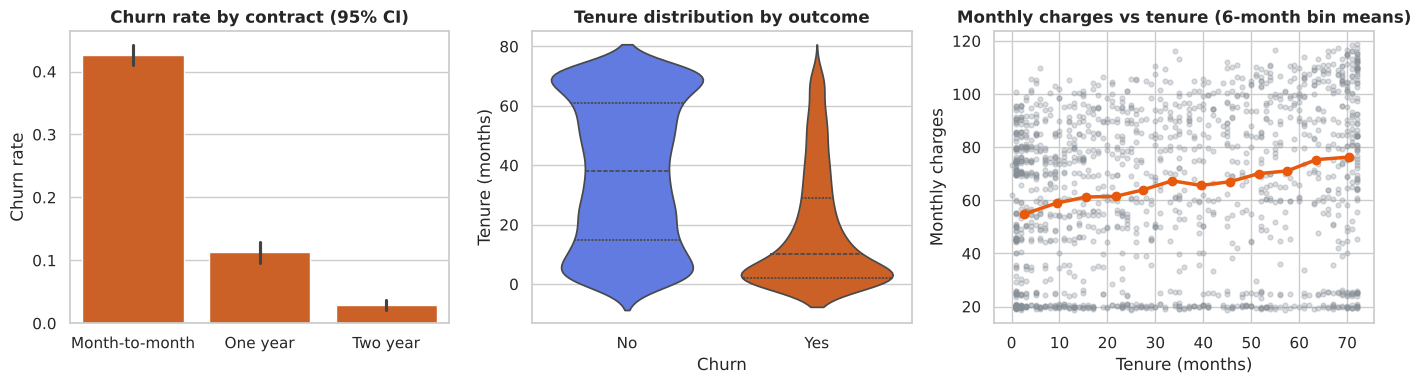

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
order = ["Month-to-month", "One year", "Two year"]
sns.barplot(data=df, x="Contract", y="churn", order=order, color=ORANGE, errorbar=("ci", 95), ax=axes[0]); axes[0].set(title="Churn rate by contract (95% CI)", ylabel="Churn rate", xlabel="")
sns.violinplot(data=df, x="Churn", y="tenure", hue="Churn", palette={"No": BLUE, "Yes": ORANGE}, inner="quartile", legend=False, ax=axes[1]); axes[1].set(title="Tenure distribution by outcome", ylabel="Tenure (months)")
smp = df.sample(1500, random_state=SEED); axes[2].scatter(smp["tenure"], smp["MonthlyCharges"], s=12, alpha=.3, color=GREY)
trend = df.groupby(pd.cut(df["tenure"], np.arange(0, 78, 6), include_lowest=True), observed=True).agg(x=("tenure", "mean"), y=("MonthlyCharges", "mean"))
axes[2].plot(trend["x"], trend["y"], color=ORANGE, lw=2.5, marker="o"); axes[2].set(title="Monthly charges vs tenure (6-month bin means)", xlabel="Tenure (months)", ylabel="Monthly charges")
plt.tight_layout(); plt.show()

**Observations:** The time-series panel shows a clear upward trend with seasonal swings that grow as the level rises (typical of multiplicative seasonality). Year-over-year growth was positive in 129 of 132 months; the only declines were February–April 1954 (as low as -4.1%), and growth was typically 10–20%. The heatmap makes the summer peak visible at a glance. On the Telco data, the confidence-interval bar chart shows the contract effect is far larger than the sampling uncertainty, the violin plot shows churned customers concentrated at short tenure, and the binned-mean line shows average monthly charges rising steadily with tenure, from about 55 in the first six months to about 76 for the longest-standing customers.

## 7. Scikit-learn: A Complete, Leak-Free Machine-Learning Workflow

**Problem:** predict whether a telecom customer will churn. **Primary metric:** ROC AUC (threshold-independent, robust to the 26.5% / 73.5% class imbalance), with average precision, recall and F1 reported as well. **Rule followed throughout:** every preprocessing step lives inside a `Pipeline`, so it is fitted only on training folds and the test set is touched exactly once.

### 7.1 Data split and preprocessing pipeline

In [17]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance

ml = raw.assign(TotalCharges=pd.to_numeric(raw["TotalCharges"], errors="coerce"))     # 11 blanks become NaN, handled inside the pipeline
y = (ml["Churn"] == "Yes").astype(int); X = ml.drop(columns=["customerID", "Churn"])
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]; cat_cols = [c for c in X.columns if c not in num_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "churn rate %.3f" % y_train.mean(), "| Test:", X_test.shape, "churn rate %.3f" % y_test.mean())
print("Numeric:", num_cols, "\nCategorical:", len(cat_cols), "columns")

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value=0)), ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
print("Encoded feature count:", make_pre().fit(X_train).get_feature_names_out().shape[0])

Train: (5634, 19) churn rate 0.265 | Test: (1409, 19) churn rate 0.265
Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges'] 
Categorical: 16 columns
Encoded feature count: 46


### 7.2 Comparing models with stratified 5-fold cross-validation

In [18]:
models = {
    "Baseline (always 'stays')": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "avg_precision": "average_precision", "f1": "f1", "recall": "recall", "precision": "precision"}
rows = {}
for name, m in models.items():
    r = cross_validate(Pipeline([("pre", make_pre()), ("model", m)]), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows[name] = {k.replace("test_", ""): r[k].mean() for k in r if k.startswith("test_")} | {"auc_std": r["test_roc_auc"].std()}
cv_table = pd.DataFrame(rows).T.round(3)
display(cv_table)

,roc_auc,avg_precision,f1,recall,precision,auc_std
Baseline (always 'stays'),0.500,0.265,0.000,0.000,0.000,0.000
Logistic regression,0.846,0.660,0.628,0.801,0.517,0.012
Random forest,0.845,0.654,0.628,0.722,0.555,0.009
Gradient boosting,0.837,0.649,0.625,0.731,0.546,0.009


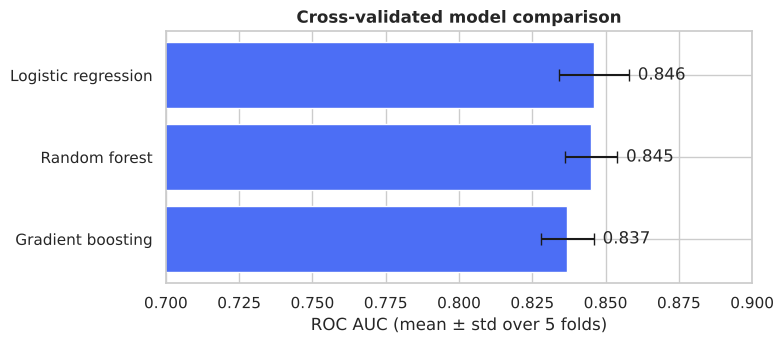

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.6))
t = cv_table.drop(index="Baseline (always 'stays')").sort_values("roc_auc")
ax.barh(t.index, t["roc_auc"], xerr=t["auc_std"], color=BLUE, capsize=4)
for i, (v, s) in enumerate(zip(t["roc_auc"], t["auc_std"])): ax.text(v + s + 0.003, i, f"{v:.3f}", va="center")
ax.set(xlim=(0.7, 0.9), xlabel="ROC AUC (mean ± std over 5 folds)", title="Cross-validated model comparison"); plt.tight_layout(); plt.show()

### 7.3 Hyperparameter tuning

In [20]:
t0 = time.time()
lr_search = GridSearchCV(Pipeline([("pre", make_pre()), ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
                         {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train, y_train)
hgb_search = RandomizedSearchCV(Pipeline([("pre", make_pre()), ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED))]),
    {"model__learning_rate": [0.02, 0.05, 0.1], "model__max_leaf_nodes": [4, 8, 15, 31], "model__min_samples_leaf": [20, 50, 100],
     "model__l2_regularization": [0, 1, 10], "model__max_iter": [100, 200, 300]},
    n_iter=15, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=SEED).fit(X_train, y_train)
print(f"Tuning took {time.time()-t0:.0f}s")
print("Logistic regression  best CV AUC %.4f with %s" % (lr_search.best_score_, lr_search.best_params_))
print("Gradient boosting    best CV AUC %.4f with %s" % (hgb_search.best_score_, hgb_search.best_params_))
best_search = max([lr_search, hgb_search], key=lambda s: s.best_score_)
best_name = "Logistic regression" if best_search is lr_search else "Gradient boosting"
best = best_search.best_estimator_
print("\nSelected on CROSS-VALIDATION only (test set not used):", best_name)

Tuning took 22s
Logistic regression  best CV AUC 0.8462 with {'model__C': 10}
Gradient boosting    best CV AUC 0.8493 with {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 4, 'model__max_iter': 200, 'model__learning_rate': 0.05, 'model__l2_regularization': 10}

Selected on CROSS-VALIDATION only (test set not used): Gradient boosting


### 7.4 Final evaluation on the untouched test set

In [21]:
proba = best.predict_proba(X_test)[:, 1]
base_pred = np.zeros(len(y_test), dtype=int)
def report(pred): return dict(accuracy=accuracy_score(y_test, pred), precision=precision_score(y_test, pred), recall=recall_score(y_test, pred), f1=f1_score(y_test, pred))
res = pd.DataFrame({"Baseline (always 'stays')": report(base_pred) | {"roc_auc": 0.5}, f"{best_name} @ 0.50": report((proba >= .5).astype(int)) | {"roc_auc": roc_auc_score(y_test, proba)}}).T
print("Test ROC AUC: %.3f | Average precision: %.3f (baseline = churn rate %.3f)" % (roc_auc_score(y_test, proba), average_precision_score(y_test, proba), y_test.mean()))
display(res.round(3))

Test ROC AUC: 0.847 | Average precision: 0.659 (baseline = churn rate 0.265)


,accuracy,precision,recall,f1,roc_auc
Baseline (always 'stays'),0.735,0.000,0.000,0.00,0.500
Gradient boosting @ 0.50,0.741,0.508,0.797,0.62,0.847


Threshold maximising F1 on out-of-fold training predictions: 0.599


,accuracy,precision,recall,f1
threshold 0.50,0.741,0.508,0.797,0.620
threshold 0.60,0.779,0.565,0.735,0.639


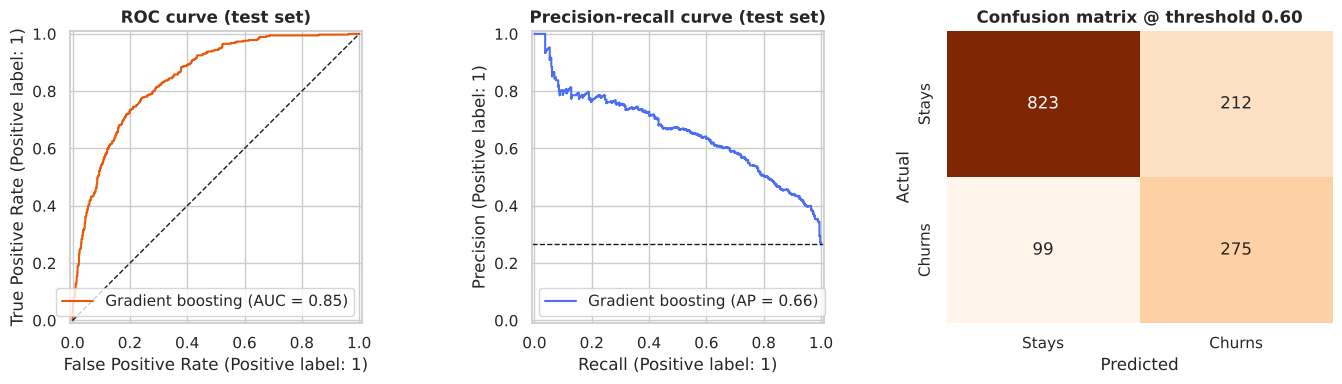

In [22]:
# Choose a decision threshold from out-of-fold predictions on the TRAINING data (never from the test set)
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof); f1s = 2 * prec * rec / (prec + rec + 1e-12)
t_best = float(thr[np.argmax(f1s[:-1])]); print("Threshold maximising F1 on out-of-fold training predictions: %.3f" % t_best)
pred_t = (proba >= t_best).astype(int)
cmp = pd.DataFrame({"threshold 0.50": report((proba >= .5).astype(int)), f"threshold {t_best:.2f}": report(pred_t)}).T.round(3)
display(cmp)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], curve_kwargs={"color": ORANGE}, name=best_name); axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curve (test set)")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[1], curve_kwargs={"color": BLUE}, name=best_name); axes[1].axhline(y_test.mean(), ls="--", color="k", lw=1); axes[1].set_title("Precision-recall curve (test set)")
cm = confusion_matrix(y_test, pred_t); sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[2], xticklabels=["Stays", "Churns"], yticklabels=["Stays", "Churns"])
axes[2].set(title=f"Confusion matrix @ threshold {t_best:.2f}", xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.show()

### 7.5 Which features drive the predictions? (permutation importance)

,feature,mean_drop_in_auc,std
0,Contract,0.0687,0.0051
1,tenure,0.0601,0.0034
2,InternetService,0.0151,0.0055
3,OnlineSecurity,0.0058,0.0014
4,TechSupport,0.0035,0.0014
5,PaymentMethod,0.0031,0.0011
6,MultipleLines,0.0027,0.0012
7,PaperlessBilling,0.0027,0.0015


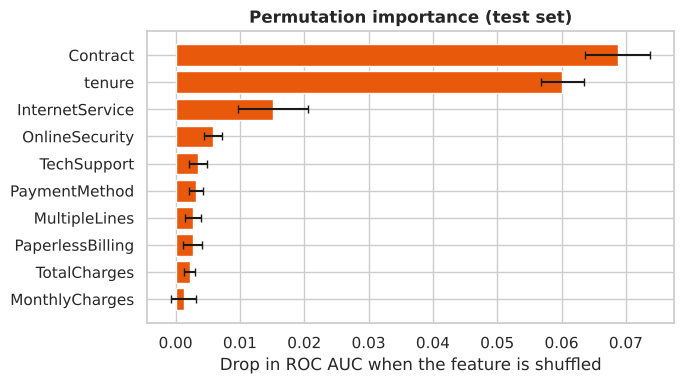

In [23]:
pi = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "mean_drop_in_auc": pi.importances_mean, "std": pi.importances_std}).sort_values("mean_drop_in_auc", ascending=False)
display(imp.head(8).round(4).reset_index(drop=True))
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4)); ax.barh(top["feature"], top["mean_drop_in_auc"], xerr=top["std"], color=ORANGE, capsize=3)
ax.set(title="Permutation importance (test set)", xlabel="Drop in ROC AUC when the feature is shuffled"); plt.tight_layout(); plt.show()

### 7.6 Saving and reloading the model

In [24]:
joblib.dump(best, "churn_model.joblib")
reloaded = joblib.load("churn_model.joblib")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], proba)
print("Saved model size: %.0f KB | reloaded predictions identical: True" % (os.path.getsize("churn_model.joblib") / 1024))
new = X_test.iloc[[0]]
print("Example customer ->", new[["tenure", "Contract", "InternetService", "MonthlyCharges"]].to_dict("records")[0])
print("Predicted churn probability: %.1f%% (actual outcome: %s)" % (100 * reloaded.predict_proba(new)[0, 1], "churned" if y_test.iloc[0] else "stayed"))

Saved model size: 133 KB | reloaded predictions identical: True
Example customer -> {'tenure': 72, 'Contract': 'Two year', 'InternetService': 'Fiber optic', 'MonthlyCharges': 114.05}
Predicted churn probability: 7.4% (actual outcome: stayed)


**Observations:**
- **Baseline matters:** always predicting 'stays' scores 73.5% accuracy but finds no churners (recall 0), so accuracy alone is misleading and ROC AUC / average precision were used instead.
- **Model comparison (5-fold CV ROC AUC):** logistic regression 0.846, random forest 0.845, default gradient boosting 0.837. The spread between models (about 0.01) is similar to the fold-to-fold standard deviation (0.009–0.012), so no model is clearly better. A simple, interpretable model is competitive here.
- **Tuning:** the tuned gradient-boosting model reached CV AUC 0.849 against 0.846 for tuned logistic regression. That edge is within noise, but it was the better CV score, so it was selected *without* looking at the test set. Strong regularisation (only 4 leaves per tree, 100 samples per leaf) was chosen, which suggests the signal is simple.
- **Test set (used once):** ROC AUC **0.847**, matching the CV estimate (0.849), so there is no sign of overfitting. Average precision is 0.659 versus 0.265 for random guessing.
- **Threshold:** at 0.50 the model finds 79.7% of churners with 50.8% precision; moving to the threshold of 0.60 chosen on training data raises precision to 56.5% and F1 from 0.620 to 0.639, while recall falls to 73.5%. The right threshold depends on the cost of a retention offer versus a lost customer, which the data cannot decide.
- **Drivers (permutation importance):** `Contract` (AUC drop 0.069) and `tenure` (0.060) dominate, followed by `InternetService` (0.015); every other feature adds 0.006 or less. This agrees with the descriptive findings of my Task 3 project.
- **Persistence:** the full pipeline (preprocessing + model) was saved at 133 KB and reloaded with identical predictions (asserted).

## 8. Git: Version-Control Workflow

A real repository is created in a temporary folder and a feature-branch workflow is executed from the notebook, so the log below is genuine output, not a mock-up.

In [25]:
import subprocess, tempfile, pathlib
repo = pathlib.Path(tempfile.mkdtemp())
def git(*args):
    r = subprocess.run(["git", "-c", "user.name=Pranav", "-c", "user.email=pranav@example.com", *args], cwd=repo, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()
print(git("init", "-b", "main"))
(repo / "analysis.py").write_text("print('churn analysis v1')\n"); (repo / "README.md").write_text("# Churn project\n")
git("add", "."); print(git("commit", "-m", "Initial commit: analysis script and README"))
print(git("switch", "-c", "feature/add-model"))
(repo / "model.py").write_text("print('train model')\n"); git("add", "model.py"); git("commit", "-m", "Add model training script")
(repo / "analysis.py").write_text("print('churn analysis v2 with tuning')\n"); git("commit", "-am", "Tune hyperparameters")
git("switch", "main"); (repo / "README.md").write_text("# Churn project\nTelco churn prediction.\n"); git("commit", "-am", "Expand README")
print(git("merge", "--no-ff", "feature/add-model", "-m", "Merge feature/add-model"))
print("\n$ git log --oneline --graph --all"); print(git("log", "--oneline", "--graph", "--all"))
print("\n$ git diff --stat HEAD~1 HEAD"); print(git("diff", "--stat", "HEAD~1", "HEAD"))
print("\n$ git ls-files"); print(git("ls-files"))

Initialized empty Git repository in /tmp/tmp3d08aiit/.git/
[main (root-commit) 0a3ffbe] Initial commit: analysis script and README
 2 files changed, 2 insertions(+)
 create mode 100644 README.md
 create mode 100644 analysis.py
Switched to a new branch 'feature/add-model'


Merge made by the 'ort' strategy.
 analysis.py | 2 +-
 model.py    | 1 +
 2 files changed, 2 insertions(+), 1 deletion(-)
 create mode 100644 model.py

$ git log --oneline --graph --all
*   098b7b2 Merge feature/add-model
|\  
| * b43b485 Tune hyperparameters
| * 609a1f5 Add model training script
* | be21759 Expand README
|/  
* 0a3ffbe Initial commit: analysis script and README

$ git diff --stat HEAD~1 HEAD
analysis.py | 2 +-
 model.py    | 1 +
 2 files changed, 2 insertions(+), 1 deletion(-)

$ git ls-files
README.md
analysis.py
model.py


**Commands used day to day for this portfolio:** `git clone`, `git status`, `git add`, `git commit -m`, `git switch -c <branch>`, `git merge`, `git log --oneline --graph`, `git diff`, `git push`, `git pull`. Good practice followed: small commits with descriptive messages, work on branches, a README, a `requirements.txt`, and no secrets or large files in the repository.

## 9. Proficiency Summary and Reflection

| Tool | Skills demonstrated | Evidence in this notebook |
|---|---|---|
| Python environment | Version report, seeds, dependency file | Section 2 |
| NumPy | Vectorization, broadcasting, masking, linear algebra | Section 3 (speed-up measured; solution matches scikit-learn) |
| Pandas | Chaining, transform, merge validation, pivot/melt, dtypes, time series | Section 4 |
| SQL | GROUP BY, CTE, window functions, JOIN, index, query plan | Section 5 (checked against Pandas) |
| Matplotlib / Seaborn | Multi-panel figures, annotation, statistical plots | Section 6 and Section 7 |
| Scikit-learn | Pipelines, CV, tuning, metrics, thresholds, importance, persistence | Section 7 |
| Git | Branching, merging, logs, diffs | Section 8 |

**Reflection:** The biggest lessons were (1) put every preprocessing step inside a pipeline so cross-validation stays leak-free, (2) report results against a baseline and choose metrics that suit imbalanced data, (3) cross-check one tool against another (SQL against Pandas, NumPy against scikit-learn), because agreement is strong evidence of correctness, and (4) treat small metric differences between models as noise unless they exceed the fold-to-fold spread. Next steps for my learning path: statsmodels for inference, model explanation with SHAP, experiment tracking, and deploying a model behind a simple API.

### Portfolio structure (as uploaded to GitHub)
```
task4-tool-mastery/
├── Tool_Mastery_Notebook.ipynb   # this notebook, fully executed
├── README.md                     # overview, results, how to run
├── requirements.txt              # dependencies
├── Telco-Customer-Churn.csv      # IBM sample data
├── flights.csv                   # airline passengers 1949-1960
└── churn_model.joblib            # trained scikit-learn pipeline
```
### Limitations
- One dataset split and one random seed: the test metrics have sampling uncertainty (a different split would shift them by a few thousandths to a couple of points).
- The Telco data is a sample dataset without dates, so the model cannot be checked for drift over time or tested on later customers.
- Permutation importance shows what the model *uses*, not what *causes* churn.
- SQLite is used for portability; larger production work would use a server database (PostgreSQL, BigQuery) and the same SQL ideas.